### TEL351 – Seminario de Telemática I
# Clase 7: Network Measures and Models
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

In [24]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math
import seaborn as sns
import random
from collections import Counter

In [2]:
def plot_graph(G, ax, title):
    pos = nx.spring_layout(G, seed=42)
    ax.set_title(title)
    nx.draw_networkx_nodes(G, pos, node_size=30, ax=ax)
    nx.draw_networkx_edges(G, pos, alpha=0.4, ax=ax)
    ax.axis('off')

In [3]:
n = 200
p = 0.02
k = 6
beta = 0.1

# Modelos de grafos

1. Erdös-Rényi
2. Watts-Strogatz
3. Barabasi-Albert

Las redes Barabási-Albert, Watts-Strogatz y Erdős-Rényi son modelos matemáticos utilizados para simular diferentes tipos de redes en el mundo real. 

In [4]:
G_er = nx.erdos_renyi_graph(n, p, seed=1)
G_ws = nx.watts_strogatz_graph(n, k, beta, seed=2)
G_ba = nx.barabasi_albert_graph(n, m=3, seed=3)

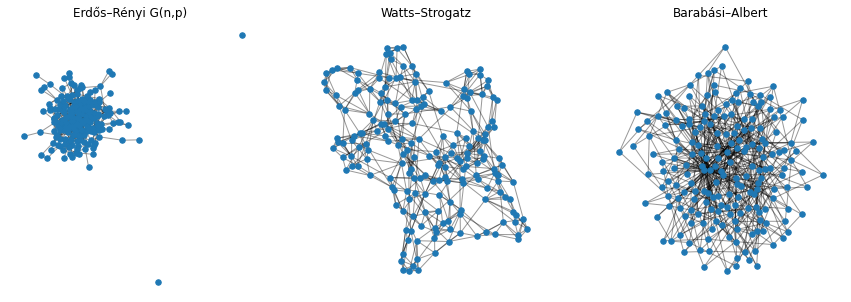

In [5]:
fig, axs = plt.subplots(1,3, figsize=(15,5))
plot_graph(G_er, axs[0], 'Erdős–Rényi G(n,p)')
plot_graph(G_ws, axs[1], 'Watts–Strogatz')
plot_graph(G_ba, axs[2], 'Barabási–Albert')
plt.show()

## Erdös-Rényi

En este modelo, comenzamos con un conjunto de nodos `n` y luego se agrega aristas entre los nodos usando una probabilidad `p`, la cual es fija y es la misma para todos los pares de nodos del grafo. Por lo tanto, una probabilidad más alta hace un grafo denso y una probabilidad más baja uno disperso. Este es un modelo simple y no se acerca a un grafo del mundo real.

In [6]:
# Erdos-Renyi model
G1 = nx.erdos_renyi_graph(n=50, p=0.2, seed=42)

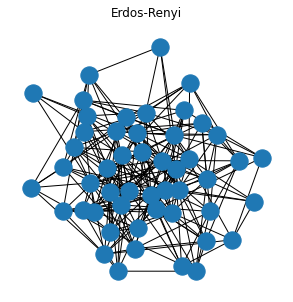

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.set_title('Erdos-Renyi')
nx.draw(G1, ax=ax)
plt.show()

## Watts-Strogatz

Este modelo comienza con una estructura similar a una cuadrícula regular con un número fijo de nodos, donde cada nodo se conecta inicialmente con sus `k` vecinos más cercanos (k/2 a la izquierda y k/2 a la derecha en el anillo). Luego, utiliza una probabilidad de recableado
`p`, lo que significa que algunas aristas se eliminan aleatoriamente de un lugar y se vuelven a conectar en otro nodo. El modelo Watts–Strogatz genera redes con la propiedad de "Small-World", que son habituales en el mundo real.

In [8]:
# Watts-Strogatz model
G2 = nx.watts_strogatz_graph(n=50, k=5, p=0.4, seed=42)

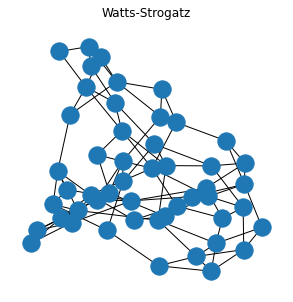

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.set_title('Watts-Strogatz')
nx.draw(G2, ax=ax)
plt.show()

## Barabasi-Albert

Este modelo sigue el principio de "los ricos se hacen más ricos", donde cada nuevo nodo que entra a la red se conecta con `m` nodos existentes, eligiéndolos con probabilidad proporcional a su grado. Esto provoca el desarrollo de unos pocos nodos altamente conectados (hubs) y varios nodos escasamente conectados en el grafo.

In [10]:
# Barabasi-Albert model
G3 = nx.barabasi_albert_graph(n=50, m=5, seed=42)

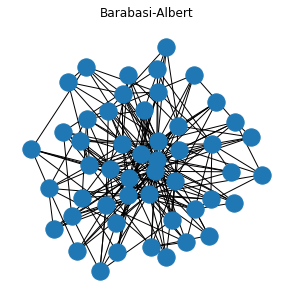

In [11]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax.set_title('Barabasi-Albert')
nx.draw(G3, ax=ax)
plt.show()

## Distribución de Grados

In [26]:
def plot_degree_distributions(models):
    """
    models: lista de tuplas (Grafo, NombreModelo)
    """
    fig, axes = plt.subplots(1, len(models), figsize=(15, 4))

    for ax, (G, model_name) in zip(axes, models):
        stats = degree_stats(G)
        degrees, counts = zip(*sorted(stats['degree_hist'].items()))

        sns.barplot(x=list(degrees), y=list(counts), ax=ax, color="skyblue")
        ax.set_title(f"{model_name}")
        ax.set_xlabel("Grado")
        ax.set_ylabel("Frecuencia")

    plt.tight_layout()
    plt.show()

In [33]:
models = [
    (G_er, "Erdős-Rényi"),
    (G_ws, "Watts-Strogatz"),
    (G_ba, "Barabási-Albert")
]

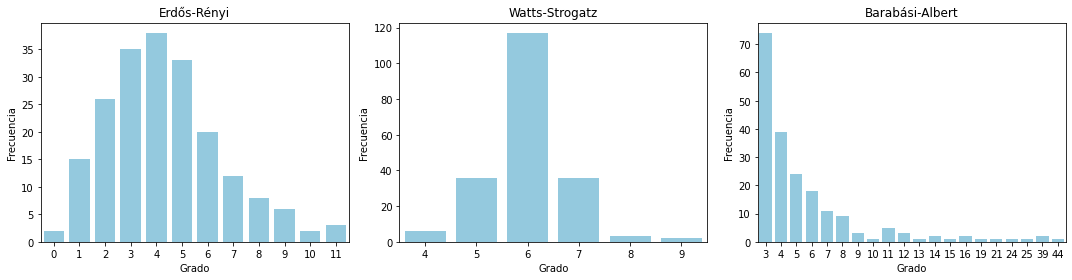

In [34]:
plot_degree_distributions(models)

# Robustez: ataques dirigidos vs aleatorios

¿Qué topología es más frágil ante la eliminación de nodos de mayor grado?

Grafos con distribución power-law (BA) son robustos a fallos aleatorios pero frágiles a ataques dirigidos a hubs.

In [12]:
def attack_robustness(G, strategy='random'):
    G = G.copy()
    n0 = G.number_of_nodes()
    
    # ordenar nodos según estrategia
    if strategy == 'degree':
        nodes_order = sorted(G.degree(), key=lambda x: x[1], reverse=True)
        nodes_order = [n for n, _ in nodes_order]
    else:
        nodes_order = list(G.nodes())
        random.shuffle(nodes_order)
    
    largest_cc = []
    removed_nodes = []
    
    for node in nodes_order:
        removed_nodes.append(node)
        G.remove_node(node)
        if G.number_of_nodes() == 0:
            largest_cc.append(0)
        else:
            largest_cc.append(len(max(nx.connected_components(G), key=len)) / n0)
    
    return largest_cc, removed_nodes

In [13]:
def plot_attack_step(G_original, removed_nodes, step, pos=None, title=""):
    G = G_original.copy()
    nodes_removed = removed_nodes[:step]
    
    # Colorear nodos
    node_colors = []
    for n in G.nodes():
        if n in nodes_removed:
            node_colors.append("red")  # removido
        else:
            node_colors.append("skyblue")  # activo
    
    if pos is None:
        pos = nx.spring_layout(G, seed=42)
    
    fig, ax = plt.subplots(figsize=(6,6))
    nx.draw(G, pos, node_color=node_colors, edge_color="gray",
            with_labels=False, node_size=80, ax=ax)
    ax.set_title(f"{title} - Paso {step} (nodos removidos: {len(nodes_removed)})")
    plt.show()

In [14]:
def plot_attack_comparison(G, removed_nodes_deg, removed_nodes_rand, step=5):
    pos = nx.spring_layout(G, seed=42)
    fig, axs = plt.subplots(1, 2, figsize=(12,6))
    
    for ax, removed_nodes, title in zip(
        axs,
        [removed_nodes_deg, removed_nodes_rand],
        ["Ataque dirigido (grado)", "Ataque aleatorio"]
    ):
        nodes_removed = removed_nodes[:step]
        node_colors = ["red" if n in nodes_removed else "skyblue" for n in G.nodes()]
        
        nx.draw(G, pos, node_color=node_colors, edge_color="gray",
                with_labels=False, node_size=80, ax=ax)
        ax.set_title(f"{title} - Paso {step}")
    
    plt.show()

In [15]:
n = 200
G_ba = nx.barabasi_albert_graph(n, m=3, seed=3)

ba_deg, removed_deg = attack_robustness(G_ba, strategy='degree')
ba_rand, removed_rand = attack_robustness(G_ba, strategy='random')

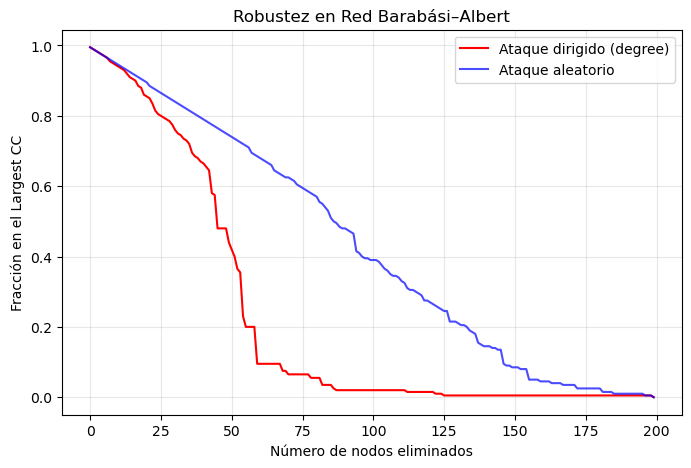

In [16]:
plt.figure(figsize=(8,5))
plt.plot(range(len(ba_deg)), ba_deg, label="Ataque dirigido (degree)", color="red")
plt.plot(range(len(ba_rand)), ba_rand, label="Ataque aleatorio", color="blue", alpha=0.7)
plt.xlabel("Número de nodos eliminados")
plt.ylabel("Fracción en el Largest CC")
plt.title("Robustez en Red Barabási–Albert")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

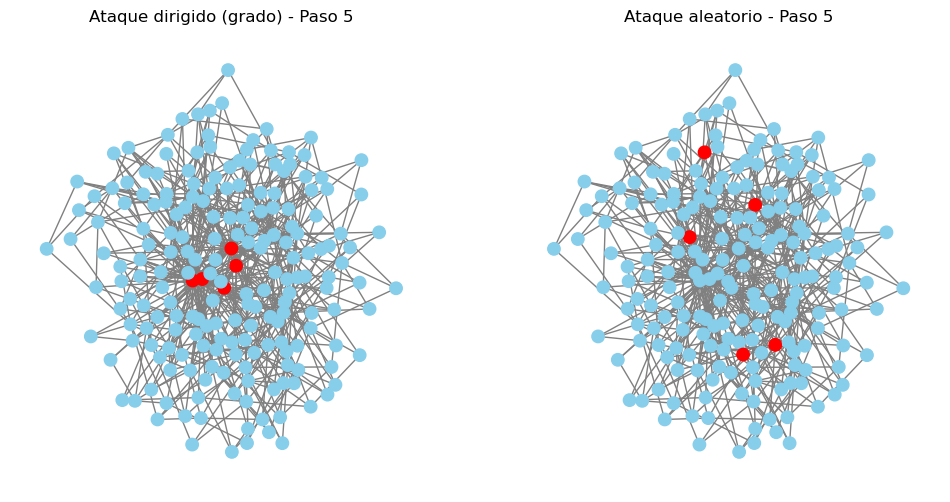

In [17]:
ba_deg, removed_deg = attack_robustness(G_ba, strategy='degree')
ba_rand, removed_rand = attack_robustness(G_ba, strategy='random')
plot_attack_comparison(G_ba, removed_deg, removed_rand, step=5)

# Introducción a la Visualización de Redes

<div align="center">
<img src="img/vis.png" alt="" width="30%" align="center" />
</div>

La visualización de redes implica representar gráficamente relaciones y estructuras entre entidades (nodos) conectadas (aristas). Facilita la comprensión de estructuras complejas, patrones de conexión, y métricas clave en una red social. Aplicaciones: Análisis de influencias, estudio de flujos de información, etc.

# Principios Básicos de Visualización de Redes

- **Nodos y Aristas:** Nodos representan entidades individuales (personas, organizaciones), y aristas representan las conexiones entre ellos (amistad, colaboración).
<div align="center">
    <img src="img/nodes-edges.png" alt="" width="80%" align="center" />
</div>

- **Atributos Visuales:**
    - **Tamaño del nodo:** Puede representar importancia o grado.
    - **Color del nodo:** Puede representar comunidad o grupo.
    - **Grosor de la arista:** Puede representar la intensidad de la relación.
<div align="center">
<img src="img/visualize.png" alt="" width="40%" align="center" />
</div>

- **Layout:** Distribución espacial de los nodos para mejorar la legibilidad.

# Karate Club Graph

Representa las interacciones entre miembros de un club de karate en una universidad. Fue introducido por Wayne W. Zachary en 1977 y es ampliamente utilizado en estudios de redes y análisis de grafos. Este grafo tiene 34 nodos, que corresponden a los miembros del club, y 78 aristas, que representan las amistades entre ellos. Es conocido por su estructura de comunidades y su capacidad para ilustrar la dinámica de formación de grupos y la propagación de influencias en redes sociales.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import numpy as np
import time

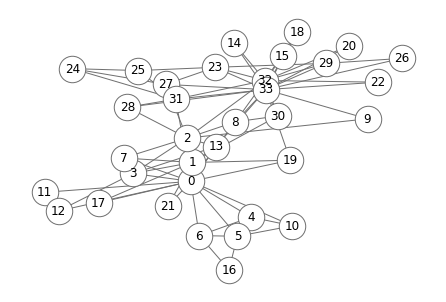

In [2]:
G = nx.karate_club_graph()
nx.draw(G, with_labels=True, node_color='white', node_size=700, edge_color='#707070', edgecolors='#707070')
plt.show()

In [3]:
def visualize_graph_variants(G):
    # Crear diferentes layouts
    pos_spring = nx.spring_layout(G)  # Layout de Fuerza
    pos_circular = nx.circular_layout(G)  # Layout Circular
    pos_spectral = nx.spectral_layout(G)  # Layout Espectral
    pos_random = nx.random_layout(G)  # Layout Aleatorio

    # Configurar la figura y los subplots
    fig, axs = plt.subplots(2, 2, figsize=(15, 12))

    # Subplot 1: Nodo color y tamaño por grado, layout de fuerza
    node_size = [100 * G.degree(n) for n in G.nodes()]
    nx.draw(G, pos_spring, with_labels=True, node_color=node_size, cmap=plt.cm.Blues, 
            node_size=node_size, edge_color='gray', ax=axs[0, 0])
    axs[0, 0].set_title('Layout de Fuerza (Nodo color y tamaño por grado)')

    # Subplot 2: Layout Circular, color por club
    node_color = ['red' if G.nodes[n]['club'] == 'Mr. Hi' else 'green' for n in G.nodes()]
    nx.draw(G, pos_circular, with_labels=True, node_color=node_color, node_size=500, 
            edge_color='gray', ax=axs[0, 1])
    axs[0, 1].set_title('Layout Circular (Color por Club)')

    # Subplot 3: Layout Espectral, Grosor de aristas por peso
    edge_width = [2 * G[u][v]['weight'] if 'weight' in G[u][v] else 1 for u, v in G.edges()]
    nx.draw(G, pos_spectral, with_labels=True, node_color='lightblue', node_size=500, 
            width=edge_width, edge_color='blue', ax=axs[1, 0])
    axs[1, 0].set_title('Layout Espectral (Grosor de aristas por peso)')

    # Subplot 4: Layout Aleatorio, Nodo color y tamaño aleatorio
    import random
    node_size = [random.randint(100, 1000) for _ in G.nodes()]
    node_color = [random.choice(['yellow', 'purple', 'cyan']) for _ in G.nodes()]
    nx.draw(G, pos_random, with_labels=True, node_color=node_color, node_size=node_size, 
            edge_color='gray', ax=axs[1, 1])
    axs[1, 1].set_title('Layout Aleatorio (Tamaño y color aleatorio)')

    # Mostrar la figura completa
    plt.tight_layout()
    plt.show()


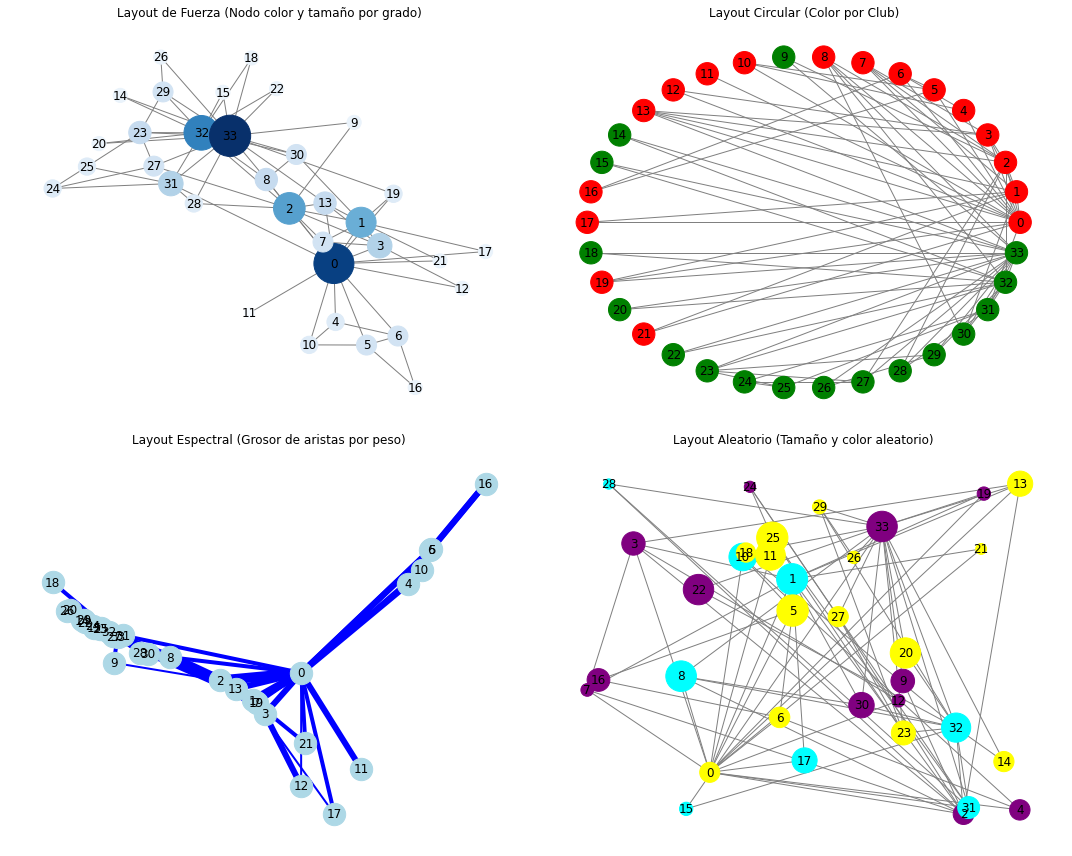

In [4]:
visualize_graph_variants(G)

# Visualización de Métricas de Redes

- **Centralidad:** Determina los nodos más importantes en una red.
- **Densidad:** Relación entre el número de aristas existentes y el número posible de aristas en la red.
- **Modularidad:** Medida de la estructura de las comunidades en la red.

In [5]:
df = pd.read_csv("star-wars-network-edges.csv")
df.head()

,source,target,weight
0,C-3PO,R2-D2,17
1,LUKE,R2-D2,13
2,OBI-WAN,R2-D2,6
3,LEIA,R2-D2,5
4,HAN,R2-D2,5


In [6]:
G = nx.from_pandas_edgelist(df, 
                            source='source',
                            target='target',
                            edge_attr='weight' )

In [7]:
weighted_degrees = dict(nx.degree(G,weight='weight'))

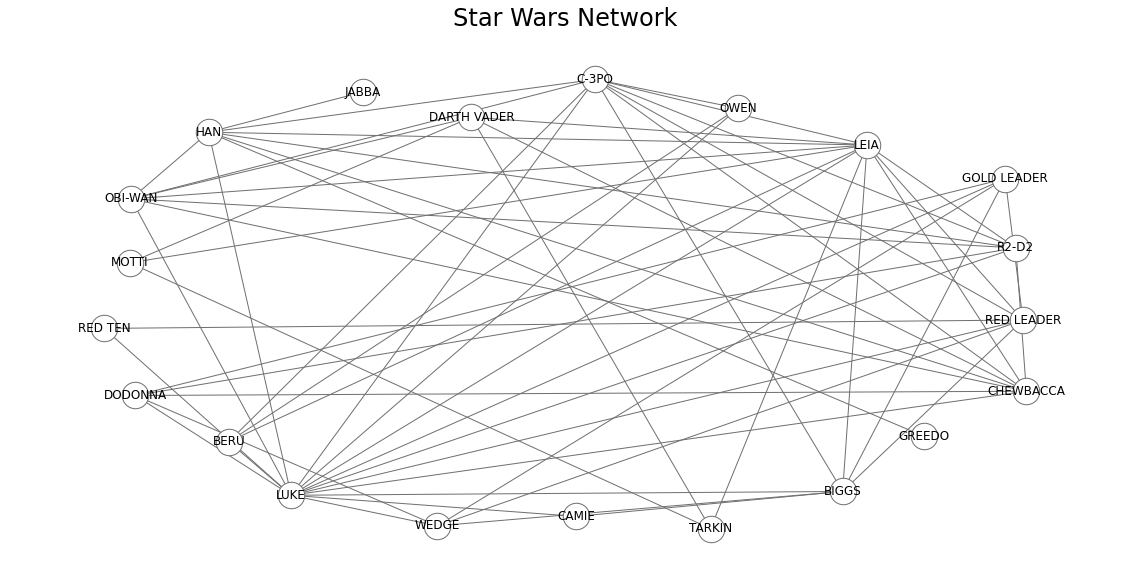

In [8]:
plt.figure(figsize=(20,10))
plt.axis('off')
plt.title('Star Wars Network',fontsize = 24)
pos = nx.spring_layout(G, k=10, seed=42)
nx.draw(G, pos, with_labels=True, node_color='white', node_size=700, edge_color='#707070', edgecolors='#707070')
plt.show()

In [9]:
def plot_metrics(G):
    # Crear diferentes layouts para una mejor visualización
    pos = nx.spring_layout(G, k=10, seed=42)  # Layout de Fuerza

    # Configurar la figura y los subplots
    fig, axs = plt.subplots(2, 3, figsize=(18, 12))

    # 1. Grado del nodo: Representado por el tamaño del nodo
    node_size = [150 * G.degree(n) for n in G.nodes()]
    nx.draw(G, pos, with_labels=True, node_color='white', node_size=node_size, edge_color='#707070', 
            edgecolors='#707070', ax=axs[0, 0])
    axs[0, 0].set_title('Grado del Nodo (Tamaño por grado)')

    # 2. Centralidad de intermediación (Betweenness Centrality): Representada por el color del nodo
    betweenness = nx.betweenness_centrality(G)
    node_color = [betweenness[n] for n in G.nodes()]
    nx.draw(G, pos, with_labels=True, node_color=node_color, cmap=plt.cm.coolwarm, 
            node_size=700, edge_color='gray', ax=axs[0, 1])
    axs[0, 1].set_title('Centralidad de Intermediación (Color por Betweenness)')

    # 3. Centralidad de cercanía (Closeness Centrality): Representada por el tamaño del nodo
    closeness = nx.closeness_centrality(G)
    node_size = [1000 * closeness[n] for n in G.nodes()]
    nx.draw(G, pos, with_labels=True, node_color='lightgreen', node_size=node_size, 
            edge_color='gray', ax=axs[0, 2])
    axs[0, 2].set_title('Centralidad de Cercanía (Tamaño por Closeness)')

    # 4. Centralidad de Eigenvector: Representada por el color del nodo
    eigenvector = nx.eigenvector_centrality(G)
    node_color = [eigenvector[n] for n in G.nodes()]
    nx.draw(G, pos, with_labels=True, node_color=node_color, cmap=plt.cm.coolwarm, 
            node_size=700, edge_color='gray', ax=axs[1, 0])
    axs[1, 0].set_title('Centralidad de Eigenvector (Color por Eigenvector)')

    # 5. Densidad del grafo: Representada por el grosor de las aristas
    for node in G.nodes():
        ns = nx.draw_networkx_nodes(G,pos,nodelist=[node], ax=axs[1, 1], node_size=500, node_color='white')
        ns.set_edgecolor('black')
    nx.draw_networkx_labels(G,pos,{n:n.replace(" ",'\n') for n in G.nodes()},font_size=11, ax=axs[1, 1],);
    for e in G.edges(data=True):
        nx.draw_networkx_edges(G,pos,[e],width=e[2]['weight']/2,edge_color='#707070', ax=axs[1, 1])
    axs[1, 1].set_title('Densidad de la Red (Grosor de aristas)')
    axs[1, 1].axis('off')

    # 6. PageRank: Representado por el tamaño del nodo
    pagerank = nx.pagerank(G)
    node_size = [5000 * pagerank[n] for n in G.nodes()]
    nx.draw(G, pos, with_labels=True, node_color='pink', node_size=node_size, edge_color='gray', ax=axs[1, 2])
    axs[1, 2].set_title('PageRank (Tamaño por PageRank)')

    # Mostrar la figura completa
    plt.tight_layout()
    plt.show()


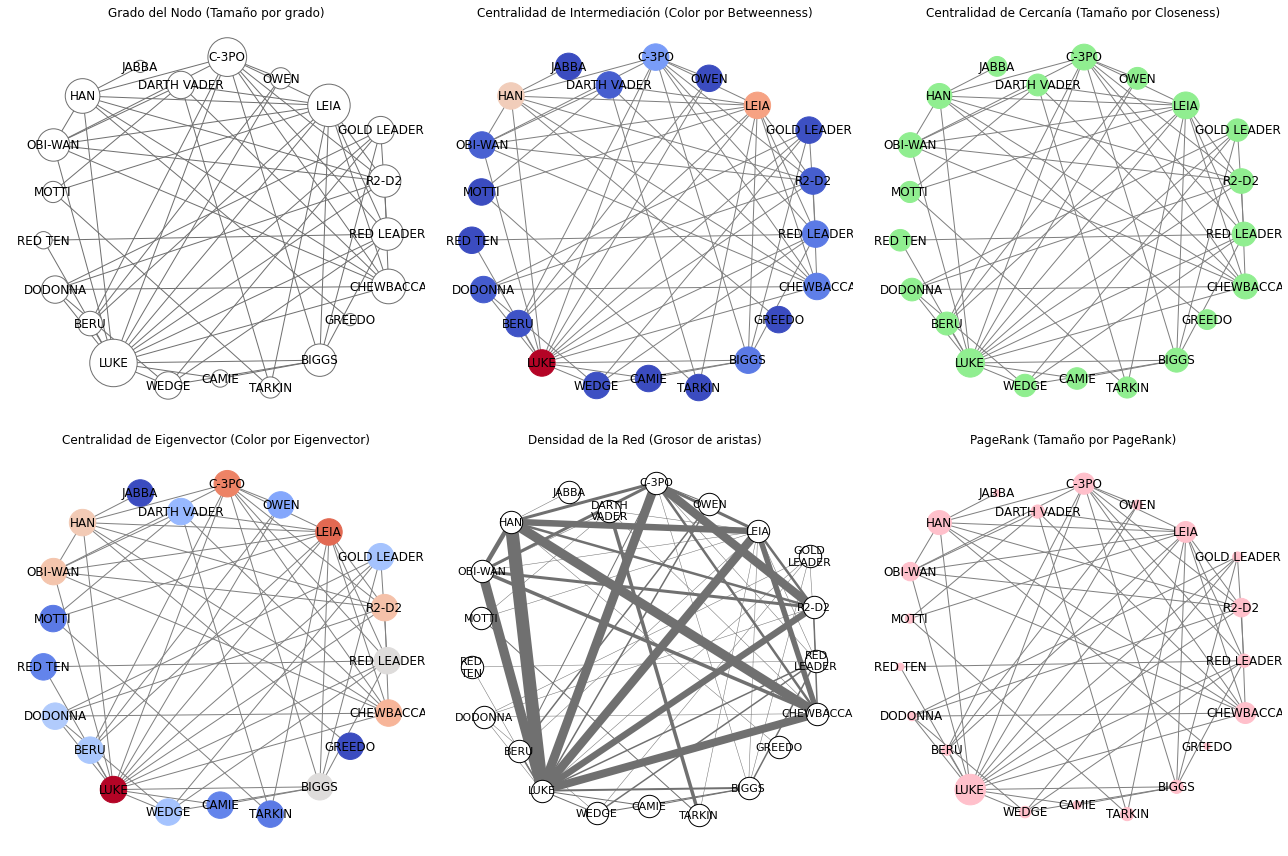

In [10]:
plot_metrics(G)

# Estilos y Layouts de Grafos

El **layout de un grafo** se refiere a la disposición espacial de sus nodos y aristas en una visualización. Es crucial porque la forma en que los nodos y aristas se presentan visualmente afecta directamente la interpretación y comprensión de la estructura y características del grafo. Un layout adecuado puede revelar patrones, relaciones, y propiedades de la red que podrían no ser evidentes de otra manera.

<div align="center">
<img src="img/layout.png" alt="" width="30%" align="center" />
</div>

In [11]:
def plot_graph_layout(G, layout_type='spring', **kwargs):
    """
    Visualiza un grafo con un layout específico y mide el tiempo de cómputo.

    Parámetros:
    G: networkx.Graph
        El grafo a visualizar.
    layout_type: str
        Tipo de layout ('spring', 'circular', 'spectral', 'shell', 'kamada_kawai', 'random').
    kwargs: dict
        Parámetros adicionales para nx.draw.

    Retorna:
    None
    """
    # Medir tiempo de cómputo
    start_time = time.time()

    # Seleccionar layout
    if layout_type == 'spring':
        pos = nx.spring_layout(G)
    elif layout_type == 'circular':
        pos = nx.circular_layout(G)
    elif layout_type == 'spectral':
        pos = nx.spectral_layout(G)
    elif layout_type == 'shell':
        pos = nx.shell_layout(G)
    elif layout_type == 'kamada_kawai':
        pos = nx.kamada_kawai_layout(G)
    elif layout_type == 'random':
        pos = nx.random_layout(G)
    else:
        raise ValueError(f"Layout '{layout_type}' no es válido.")

    # Tiempo de cómputo
    computation_time = time.time() - start_time

    # Dibujar el grafo
    plt.figure(figsize=(8, 6))
    nx.draw(G, pos, with_labels=True, **kwargs)
    plt.title(f"Layout: {layout_type.capitalize()} (Tiempo de cómputo: {computation_time:.4f} segundos)")
    plt.show()

## Layout de Fuerza (Force-Directed Layout)

El `spring_layout` de `networkx` es un layout de fuerza (Force-Directed), donde las aristas actúan como resortes entre los nodos y las fuerzas de repulsión actúan entre todos los nodos. Este layout es adecuado para la mayoría de los grafos, ya que tiende a distribuir los nodos de manera uniforme y minimiza la superposición de aristas. Es adecuado cuando se necesita una distribución uniforme y legible de los nodos.

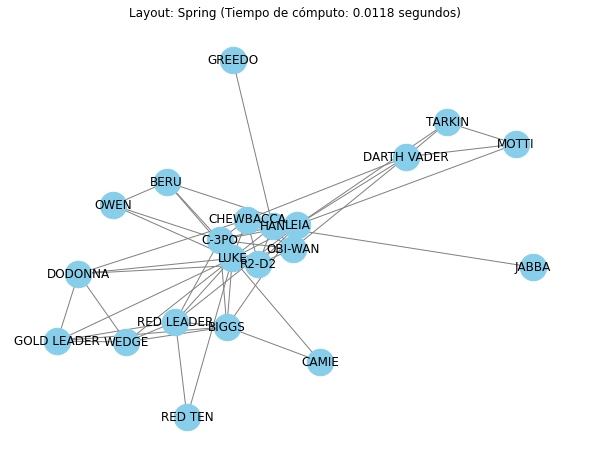

In [12]:
plot_graph_layout(G, layout_type='spring', node_color='skyblue', node_size=700, edge_color='gray')

## Layout Circular

El `circular_layout` coloca los nodos en un círculo, es ideal para visualizar grafos donde la simetría es importante o en situaciones donde los nodos tienen un orden natural (por ejemplo, ciclos). Se utiliza mejor cuando el número de nodos es pequeño, ya que en grafos grandes puede volverse caótico.

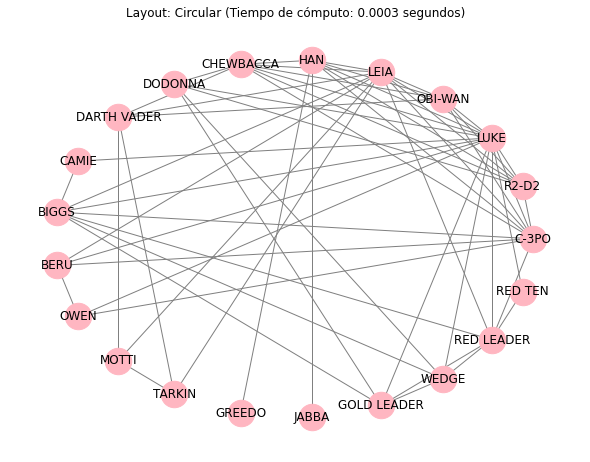

In [13]:
plot_graph_layout(G, layout_type='circular', node_color='lightpink', node_size=700, edge_color='gray')

## Layout Jerárquico (Layout de Árbol)

El `shell_layout` es un tipo de layout jerárquico que organiza los nodos en capas concéntricas. Este layout es útil para visualizar grafos con estructura jerárquica o árboles. Se puede utilizar cuando se quiere destacar la estructura en capas del grafo.

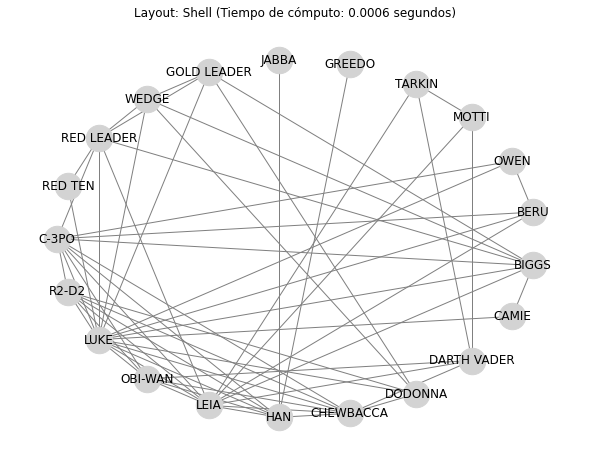

In [14]:
plot_graph_layout(G, layout_type='shell', node_color='lightgray', node_size=700, edge_color='gray')

## Layout Espectral

El `spectral_layout` utiliza el análisis espectral de la matriz Laplaciana del grafo para disponer los nodos. Este layout es útil para resaltar la estructura global del grafo, como comunidades o subgrupos. Se recomienda cuando se necesita una visión global del grafo, capturando la distribución general.

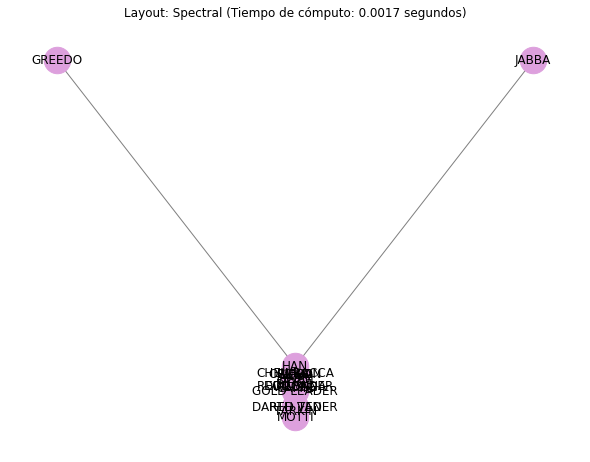

In [15]:
plot_graph_layout(G, layout_type='spectral', node_color='plum', node_size=700, edge_color='gray')

## Layout Aleatorio

El `random_layout` coloca los nodos en posiciones aleatorias. Aunque no suele ser útil para análisis, puede ser una opción rápida cuando se necesita una disposición básica o como punto de comparación. Cuando se necesita una disposición rápida y no se requiere ningún análisis específico de la estructura.

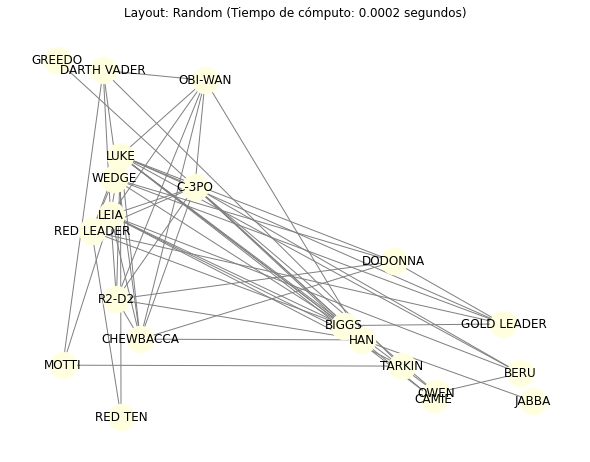

In [16]:
plot_graph_layout(G, layout_type='random', node_color='lightyellow', node_size=700, edge_color='gray')

# Visualización Dinámica de Redes

Redes que cambian con el tiempo, donde nodos y aristas pueden aparecer o desaparecer. Se usan animaciones o sliders para representar la evolución de la red. Aplicaciones: Seguimiento de la difusión de información en tiempo real, análisis de cambios en las estructuras de poder.

In [17]:
import networkx as nx
import plotly.graph_objects as go
import random

def dynamic_network_evolution(n_iterations=20, n_nodes=10, edge_density=0.2):
    # Función para actualizar la red en cada iteración
    def update_graph(G):
        # Añadir un nuevo nodo con algunas aristas aleatorias
        new_node = len(G.nodes)
        G.add_node(new_node)
        num_edges = random.randint(1, 3)
        for _ in range(num_edges):
            neighbor = random.choice(list(G.nodes))
            G.add_edge(new_node, neighbor)

        # Eliminar aleatoriamente una arista
        if len(G.edges) > 0:
            edge_to_remove = random.choice(list(G.edges))
            G.remove_edge(*edge_to_remove)

    # Crear una red inicial
    G = nx.erdos_renyi_graph(n_nodes, edge_density)

    # Crear tramas para cada iteración
    frames = []
    for i in range(n_iterations):
        update_graph(G)
        pos = nx.spring_layout(G)  # Actualizar posiciones de los nodos

        edge_x = []
        edge_y = []
        for edge in G.edges():
            x0, y0 = pos[edge[0]]
            x1, y1 = pos[edge[1]]
            edge_x.extend([x0, x1, None])
            edge_y.extend([y0, y1, None])

        node_x = [pos[node][0] for node in G.nodes()]
        node_y = [pos[node][1] for node in G.nodes()]

        edge_trace = go.Scatter(x=edge_x, y=edge_y, line=dict(width=0.5, color='#888'), 
                                hoverinfo='none', mode='lines')
        node_trace = go.Scatter(x=node_x, y=node_y, mode='markers+text', text=[str(node) for node in G.nodes()],
                                textposition="top center", marker=dict(color='skyblue', size=10), 
                                hoverinfo='text')

        frames.append(go.Frame(data=[edge_trace, node_trace], name=str(i)))

    # Configuración de la figura inicial
    fig = go.Figure(
        data=frames[0].data,
        layout=go.Layout(
            title="Evolución de la Red Dinámica",
            titlefont_size=16,
            showlegend=False,
            updatemenus=[dict(type="buttons", showactive=False, buttons=[dict(label="Play", 
                                                                              method="animate", 
                                                                              args=[None])])],
            sliders=[dict(steps=[dict(method="animate", args=[[str(i)], dict(mode="immediate", 
                                                                             frame=dict(duration=500, 
                                                                                        redraw=True))],
                                      label=f'Iteración {i + 1}') for i in range(len(frames))])])
    )

    # Añadir todas las frames (para cada iteración)
    fig.frames = frames

    # Mostrar la figura
    fig.show()

In [18]:
dynamic_network_evolution(n_iterations=20, n_nodes=10, edge_density=0.2)

# Fenómeno de Propagación de Información

La información se difunde rápidamente en redes sociales a través de conexiones entre usuarios, donde las ideas se propagan de un nodo a otro, afectando a un gran número de individuos en un corto período.

In [19]:
import networkx as nx
import plotly.graph_objects as go
import random

def simulate_information_spread(prob_spread=0.3, n_nodes=30, edge_density=0.2):
    # Crear una red inicial
    G = nx.erdos_renyi_graph(n_nodes, edge_density)

    # Inicializar un nodo como el primer difusor de información
    infected_nodes = {random.choice(list(G.nodes))}

    # Calcular las posiciones una vez y mantenerlas fijas
    pos = nx.spring_layout(G)

    # Crear tramas para cada iteración
    frames = []
    for i in range(20):
        # Crear una copia de los nodos infectados para iterar sobre ellos
        new_infected_nodes = set(infected_nodes)

        for node in infected_nodes:
            for neighbor in G.neighbors(node):
                if neighbor not in infected_nodes and random.random() < prob_spread:
                    new_infected_nodes.add(neighbor)

        # Actualizar la lista de nodos infectados
        infected_nodes = new_infected_nodes

        # Graficar las aristas
        edge_x = []
        edge_y = []
        for edge in G.edges():
            x0, y0 = pos[edge[0]]
            x1, y1 = pos[edge[1]]
            edge_x.extend([x0, x1, None])
            edge_y.extend([y0, y1, None])

        # Graficar los nodos
        node_x = [pos[node][0] for node in G.nodes()]
        node_y = [pos[node][1] for node in G.nodes()]

        # Definir los colores: infectados en rojo, no infectados en azul
        node_color = ['red' if node in infected_nodes else 'skyblue' for node in G.nodes()]

        edge_trace = go.Scatter(x=edge_x, y=edge_y, line=dict(width=0.5, color='#888'), 
                                hoverinfo='none', mode='lines')
        node_trace = go.Scatter(x=node_x, y=node_y, mode='markers+text', text=[str(node) for node in G.nodes()],
                                textposition="top center", 
                                marker=dict(color=node_color, size=10), hoverinfo='text')

        frames.append(go.Frame(data=[edge_trace, node_trace], name=str(i)))

    # Configuración de la figura inicial
    fig = go.Figure(
        data=frames[0].data,
        layout=go.Layout(
            title="Propagación de Información en una Red Social",
            titlefont_size=16,
            showlegend=False,
            updatemenus=[dict(type="buttons", showactive=False, buttons=[dict(label="Play", 
                                                                              method="animate", 
                                                                              args=[None])])],
            sliders=[dict(steps=[dict(method="animate", args=[[str(i)], dict(mode="immediate", 
                                                                             frame=dict(duration=500, 
                                                                                        redraw=True))],
                                      label=f'Iteración {i + 1}') for i in range(len(frames))])])
    )

    # Añadir todas las frames (para cada iteración)
    fig.frames = frames

    # Mostrar la figura
    fig.show()


In [20]:
# Ejemplo de uso con probabilidad de difusión del 50% y densidad de aristas del 30%
simulate_information_spread(prob_spread=0.5, n_nodes=30, edge_density=0.3)

# Fenómeno: Formación de Opiniones

Las opiniones de los individuos se forman y evolucionan a través de la interacción con otros usuarios, donde las ideas y creencias son influenciadas y modificadas según el entorno social y las conexiones en la red.

In [21]:
import networkx as nx
import plotly.graph_objects as go
import random

def opinion_formation(n_nodes=30, edge_density=0.2):
    # Crear una red inicial
    G = nx.erdos_renyi_graph(n_nodes, edge_density)

    # Asignar una opinión inicial binaria (0 o 1) a cada nodo
    opinions = {node: random.choice([0, 1]) for node in G.nodes}

    # Calcular las posiciones una vez y mantenerlas fijas
    pos = nx.spring_layout(G)

    # Crear tramas para cada iteración
    frames = []
    for i in range(20):
        # Crear una copia de las opiniones para iterar sobre ellas
        new_opinions = opinions.copy()

        for node in G.nodes:
            # Calcular la opinión promedio de los vecinos
            neighbors = list(G.neighbors(node))
            if neighbors:
                neighbor_opinion_avg = sum(opinions[neighbor] for neighbor in neighbors) / len(neighbors)
                # Actualizar la opinión del nodo hacia la media de las opiniones de sus vecinos
                new_opinions[node] = (opinions[node] + neighbor_opinion_avg) / 2

        # Actualizar las opiniones en la red
        opinions = new_opinions

        # Graficar las aristas
        edge_x = []
        edge_y = []
        for edge in G.edges():
            x0, y0 = pos[edge[0]]
            x1, y1 = pos[edge[1]]
            edge_x.extend([x0, x1, None])
            edge_y.extend([y0, y1, None])

        # Graficar los nodos
        node_x = [pos[node][0] for node in G.nodes()]
        node_y = [pos[node][1] for node in G.nodes()]

        # Definir los colores: opiniones se reflejan en una escala de colores
        node_color = [f'rgba({255 * opinions[node]}, {0}, {255 * (1 - opinions[node])}, 1)' for node in G.nodes()]

        edge_trace = go.Scatter(x=edge_x, y=edge_y, line=dict(width=0.5, color='#888'), 
                                hoverinfo='none', mode='lines')
        node_trace = go.Scatter(x=node_x, y=node_y, mode='markers+text', 
                                text=[f'{node}: {opinions[node]:.2f}' for node in G.nodes()],
                                textposition="top center", marker=dict(color=node_color, size=10), 
                                hoverinfo='text')

        frames.append(go.Frame(data=[edge_trace, node_trace], name=str(i)))

    # Configuración de la figura inicial
    fig = go.Figure(
        data=frames[0].data,
        layout=go.Layout(
            title="Formación de Opiniones en una Red Social",
            titlefont_size=16,
            showlegend=False,
            updatemenus=[dict(type="buttons", showactive=False, buttons=[dict(label="Play", 
                                                                              method="animate", 
                                                                              args=[None])])],
            sliders=[dict(steps=[dict(method="animate", args=[[str(i)], dict(mode="immediate", 
                                                                             frame=dict(duration=500, 
                                                                                        redraw=True))],
                                      label=f'Iteración {i + 1}') for i in range(len(frames))])])
    )

    # Añadir todas las frames (para cada iteración)
    fig.frames = frames

    # Mostrar la figura
    fig.show()


In [22]:
opinion_formation(n_nodes=30, edge_density=0.2)

# Fenómeno: Consenso y Convencimiento

En redes sociales, los usuarios pueden tener opiniones polarizadas, pero a medida que interactúan, las opiniones de los individuos tienden a moderarse debido a la influencia de sus conexiones cercanas, lo que conduce a un consenso en la comunidad, reduciendo la polarización inicial.

In [23]:
import networkx as nx
import plotly.graph_objects as go
import random

def opinion_consensus_simulation(n_nodes=15, edge_density=0.2, dynamic_positions=True):
    # Crear una red inicial
    G = nx.erdos_renyi_graph(n_nodes, edge_density)

    # Asignar una opinión inicial binaria (0 o 1) a cada nodo
    opinions = {node: random.choice([0, 1]) for node in G.nodes()}
    nx.set_node_attributes(G, opinions, 'opinion')

    # Calcular las posiciones iniciales
    pos = nx.spring_layout(G)

    # Crear tramas para cada iteración
    frames = []

    # Iteración 0: Visualización inicial con opiniones binarias
    edge_x = []
    edge_y = []
    for edge in G.edges():
        x0, y0 = pos[edge[0]]
        x1, y1 = pos[edge[1]]
        edge_x.extend([x0, x1, None])
        edge_y.extend([y0, y1, None])

    node_x = [pos[node][0] for node in G.nodes()]
    node_y = [pos[node][1] for node in G.nodes()]
    node_color = ['red' if opinions[node] == 0 else 'blue' for node in G.nodes()]

    edge_trace = go.Scatter(x=edge_x, y=edge_y, line=dict(width=0.5, color='#888'), 
                            hoverinfo='none', mode='lines')
    node_trace = go.Scatter(x=node_x, y=node_y, mode='markers+text', 
                            text=[f'{node}: {opinions[node]}' for node in G.nodes()],
                            textposition="top center", marker=dict(color=node_color, size=10), 
                            hoverinfo='text')

    frames.append(go.Frame(data=[edge_trace, node_trace], name='0'))

    # Iteraciones posteriores: Actualización de opiniones
    for i in range(1, 21):
        # Crear una copia de las opiniones para iterar sobre ellas
        new_opinions = opinions.copy()

        for node in G.nodes:
            # Calcular la opinión promedio de los vecinos
            neighbors = list(G.neighbors(node))
            if neighbors:
                neighbor_opinion_avg = sum(opinions[neighbor] for neighbor in neighbors) / len(neighbors)
                # Actualizar la opinión del nodo hacia la media de las opiniones de sus vecinos
                new_opinions[node] = (opinions[node] + neighbor_opinion_avg) / 2

        # Actualizar las opiniones en la red
        opinions = new_opinions
        nx.set_node_attributes(G, opinions, 'opinion')

        # Si las posiciones son dinámicas, actualizar las posiciones
        if dynamic_positions:
            pos = nx.spring_layout(G, pos=pos, fixed=None)

        # Graficar las aristas
        edge_x = []
        edge_y = []
        for edge in G.edges():
            x0, y0 = pos[edge[0]]
            x1, y1 = pos[edge[1]]
            edge_x.extend([x0, x1, None])
            edge_y.extend([y0, y1, None])

        # Graficar los nodos
        node_x = [pos[node][0] for node in G.nodes()]
        node_y = [pos[node][1] for node in G.nodes()]
        node_color = ['red' if opinions[node] < 0.5 else 'blue' for node in G.nodes()]

        edge_trace = go.Scatter(x=edge_x, y=edge_y, line=dict(width=0.5, color='#888'), 
                                hoverinfo='none', mode='lines')
        node_trace = go.Scatter(x=node_x, y=node_y, mode='markers+text', 
                                text=[f'{node}: {opinions[node]:.2f}' for node in G.nodes()],
                                textposition="top center", 
                                marker=dict(color=node_color, size=10), hoverinfo='text')

        frames.append(go.Frame(data=[edge_trace, node_trace], name=str(i)))

    # Configuración de la figura inicial
    fig = go.Figure(
        data=frames[0].data,
        layout=go.Layout(
            title="Simulación de Formación de Opiniones y Consenso",
            titlefont_size=16,
            showlegend=False,
            updatemenus=[dict(type="buttons", showactive=False, 
                              buttons=[dict(label="Play", method="animate", args=[None])])],
            sliders=[dict(steps=[dict(method="animate", args=[[str(i)], 
                                                              dict(mode="immediate", 
                                                                   frame=dict(duration=500, 
                                                                              redraw=True))],
                                      label=f'Iteración {i}') for i in range(len(frames))])])
    )

    # Añadir todas las frames (para cada iteración)
    fig.frames = frames

    # Mostrar la figura
    fig.show()

In [24]:
opinion_consensus_simulation(n_nodes=15, edge_density=0.2, dynamic_positions=False)